# E1: compare clip and speaker weights for both feature studies

Compare the saved 39-feature and 91-feature studies on validation and test data.
For each classifier, compare the full feature pool with its saved selected count.

- **Equal clip weights:** each clip has equal influence within its class.
- **Equal speaker weights:** each speaker has equal total influence within its class.

Both scores give the two classes equal influence. Keep models, predictions, and feature
counts fixed. This notebook changes scoring weights only. It does not train a model,
select features, or change a decision threshold.

Validation predictions come from training-only models. Test predictions come from
models refitted on training plus validation. Read the two splits separately.
The saved selections can belong to an earlier selection rule. Check the run summary below.
Rerun the feature studies to replace those selections; this notebook does not replace them.

## 1. Load saved predictions

Complete both feature studies through test evaluation first.
Use `study_results.joblib` for the current saved selections and predictions.
For older files without test predictions, use `report_evidence.json` only when its
identities, selected counts, and test scores match the study results.
Stop if those checks fail. Do not combine different saved runs.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, f1_score

PROJECT_ROOT = Path.cwd()
STUDY_DIR = PROJECT_ROOT / 'outputs' / 'e1_feature_study_accent_3to6s_upstream'
POOLS = (39, 91)
MODEL_NAMES = ('logistic_regression', 'svm', 'random_forest')
MODEL_LABELS = {'logistic_regression': 'Logistic Regression', 'svm': 'SVM',
                'random_forest': 'Random Forest'}
SPLITS = ('validation', 'test')
sys.path.insert(0, str(PROJECT_ROOT))
from scripts.accent_study_data import load_shared_39_cache

shared = load_shared_39_cache(PROJECT_ROOT, STUDY_DIR)
metadata = shared['metadata']
identities = {key: shared[key] for key in ('cache_id', 'dataset_id')}
del shared
studies, prediction_sets, run_rows = {}, {}, []


def score_lookup(records):
    result = {}
    for record in records:
        key = (record['model'], int(record['feature_count']))
        values = (float(record['balanced_accuracy']), float(record['macro_f1']))
        if key in result and result[key] != values:
            raise ValueError(f'Conflicting saved scores: {key}')
        result[key] = values
    return result


for pool in POOLS:
    directory = STUDY_DIR / ('results' if pool == 39 else 'results_91')
    study = joblib.load(directory / 'study_results.joblib')
    if study['dataset_id'] != identities['dataset_id']:
        raise ValueError(f'{pool}: dataset identity differs from the upstream data.')
    if pool == 39:
        expected_cache = identities['cache_id']
    else:
        with np.load(STUDY_DIR / 'acoustic_features_91.npz', allow_pickle=False) as cache:
            expected_cache = str(cache['cache_id'].item())
        if study['base_cache_id'] != identities['cache_id']:
            raise ValueError('91: base cache differs from the current 39-feature cache.')
    if study['cache_id'] != expected_cache:
        raise ValueError(f'{pool}: feature cache identity differs.')
    if set(study['selected_counts']) != set(MODEL_NAMES):
        raise ValueError(f'{pool}: expected all three classifiers.')
    if any(type(k) is not int or not 1 <= k <= pool for k in study['selected_counts'].values()):
        raise ValueError(f'{pool}: invalid selected counts.')

    if 'test_predictions' in study:
        test_rows = study['test_predictions']
        test_source = 'study_results.joblib'
    else:
        evidence = json.loads((directory / 'report_evidence.json').read_text())
        for key in ('cache_id', 'dataset_id', 'selected_counts'):
            if evidence[key] != study[key]:
                raise ValueError(f'{pool}: older test evidence has a different {key}. Rerun the feature study.')
        if score_lookup(evidence['test_scores']) != score_lookup(study['test_scores']):
            raise ValueError(f'{pool}: older test evidence has different test scores. Rerun the feature study.')
        test_rows = evidence['test_predictions']
        test_source = 'report_evidence.json (matched older results)'
        print(f'{pool}: using matched older test evidence. It may precede the current notebook selection rule.')
    studies[pool] = study
    for split, rows in [('validation', study['validation_predictions']), ('test', test_rows)]:
        frame = pd.DataFrame(rows)
        if 'split' in frame and not frame['split'].eq(split).all():
            raise ValueError(f'{pool}: incorrect split in {split} predictions.')
        frame['split'] = split
        prediction_sets[(pool, split)] = frame
    run_rows.append({'feature_pool': pool, **study['selected_counts'],
                     'test_prediction_source': test_source})

display(pd.DataFrame(run_rows))

39: using matched older test evidence. It may precede the current notebook selection rule.


ValueError: 91: older test evidence has a different selected_counts. Rerun the feature study.

## 2. Check clips, labels, speakers, and saved test scores

Each model must use the complete provided split with no duplicate clips.
The cache loader checks speaker separation and excludes reserved Common Voice Singaporean clips.
Check each saved test score against its predictions before comparing weights.

In [ ]:
for (pool, split), frame in prediction_sets.items():
    expected = metadata.loc[metadata['split'] == split, ['speaker_group', 'label']].rename(
        columns={'label': 'true_label'}).sort_index()
    required = {(model, count) for model in MODEL_NAMES
                for count in {pool, studies[pool]['selected_counts'][model]}}
    actual_keys = set(zip(frame['model'], frame['feature_count']))
    if actual_keys != required:
        raise ValueError(f'{pool}, {split}: missing or unexpected model/count combinations.')
    references = score_lookup(studies[pool]['test_scores']) if split == 'test' else None
    for (model, count), rows in frame.groupby(['model', 'feature_count']):
        if rows['clip_id'].duplicated().any():
            raise ValueError(f'{pool}, {split}, {model}, {count}: duplicate clips.')
        actual = rows.set_index('clip_id')[['speaker_group', 'true_label']].sort_index()
        if not actual.equals(expected):
            raise ValueError(f'{pool}, {split}, {model}, {count}: clip metadata differs.')
        if set(rows['true_label']) != {0, 1} or not set(rows['prediction']) <= {0, 1}:
            raise ValueError('Expected binary labels and predictions.')
        if references is not None:
            observed = (balanced_accuracy_score(rows['true_label'], rows['prediction']),
                        f1_score(rows['true_label'], rows['prediction'], average='macro'))
            if not np.allclose(observed, references[(model, count)], rtol=0, atol=1e-12):
                raise ValueError(f'{pool}, {model}, {count}: test predictions differ from saved scores.')
print('Checks passed for both pools and both splits.')

Checks passed for both pools and both splits.


## 3. Calculate both scores

Give each clip weight `1 / number of clips from its speaker` for the speaker-weighted score.
For example, ten clips from one speaker each receive weight 0.1. That speaker has total weight 1.
Both scores remain balanced across the two classes.
If the selected count equals the full pool, show one row for that model.

In [ ]:
def calculate_scores(rows):
    clips_per_speaker = rows.groupby('speaker_group')['clip_id'].transform('size')
    weighted = balanced_accuracy_score(rows['true_label'], rows['prediction'],
                                       sample_weight=1.0 / clips_per_speaker)
    ordinary = balanced_accuracy_score(rows['true_label'], rows['prediction'])
    return {'speaker_weighted_balanced_accuracy_pct': 100 * weighted,
            'ordinary_balanced_accuracy_pct': 100 * ordinary,
            'clip_minus_speaker_points': 100 * (ordinary - weighted)}


comparison_rows = []
for pool in POOLS:
    for split in SPLITS:
        frame = prediction_sets[(pool, split)]
        for model in MODEL_NAMES:
            selected = studies[pool]['selected_counts'][model]
            baseline_rows = frame.loc[(frame['model'] == model) & (frame['feature_count'] == pool)]
            baseline = calculate_scores(baseline_rows)
            roles = [('Full / selected', pool)] if selected == pool else [('Full', pool), ('Selected', selected)]
            for role, count in roles:
                rows = frame.loc[(frame['model'] == model) & (frame['feature_count'] == count)]
                scores = calculate_scores(rows)
                comparison_rows.append({'feature_pool': pool, 'split': split,
                    'model': model, 'role': role, 'feature_count': count,
                    'clips': len(rows), 'speakers': rows['speaker_group'].nunique(), **scores,
                    'speaker_weighted_gain_from_full_points': scores['speaker_weighted_balanced_accuracy_pct'] - baseline['speaker_weighted_balanced_accuracy_pct'],
                    'ordinary_gain_from_full_points': scores['ordinary_balanced_accuracy_pct'] - baseline['ordinary_balanced_accuracy_pct']})
comparison = pd.DataFrame(comparison_rows)
for split in SPLITS:
    print(split.title())
    display(comparison.loc[comparison['split'] == split].round(3))

Validation


,feature_pool,split,model,role,feature_count,clips,speakers,speaker_weighted_balanced_accuracy_pct,ordinary_balanced_accuracy_pct,clip_minus_speaker_points,speaker_weighted_gain_from_full_points,ordinary_gain_from_full_points
0,39,validation,logistic_regression,Full,39,1742,687,89.352,88.564,-0.787,0.000,0.000
1,39,validation,logistic_regression,Selected,35,1742,687,89.715,89.133,-0.582,0.363,0.569
2,39,validation,svm,Full / selected,39,1742,687,93.370,92.527,-0.843,0.000,0.000
3,39,validation,random_forest,Full / selected,39,1742,687,90.951,89.546,-1.405,0.000,0.000
8,91,validation,logistic_regression,Full,91,1742,687,91.890,90.341,-1.549,0.000,0.000
9,91,validation,logistic_regression,Selected,30,1742,687,91.712,90.263,-1.449,-0.178,-0.078
10,91,validation,svm,Full,91,1742,687,95.272,93.536,-1.736,0.000,0.000
11,91,validation,svm,Selected,25,1742,687,94.240,93.115,-1.125,-1.031,-0.421
12,91,validation,random_forest,Full,91,1742,687,92.547,90.552,-1.996,0.000,0.000
13,91,validation,random_forest,Selected,25,1742,687,92.292,89.944,-2.348,-0.255,-0.608


Test


,feature_pool,split,model,role,feature_count,clips,speakers,speaker_weighted_balanced_accuracy_pct,ordinary_balanced_accuracy_pct,clip_minus_speaker_points,speaker_weighted_gain_from_full_points,ordinary_gain_from_full_points
4,39,test,logistic_regression,Full,39,1736,684,90.180,88.579,-1.601,0.000,0.000
5,39,test,logistic_regression,Selected,35,1736,684,90.533,88.981,-1.551,0.353,0.402
6,39,test,svm,Full / selected,39,1736,684,94.153,93.129,-1.024,0.000,0.000
7,39,test,random_forest,Full / selected,39,1736,684,90.735,89.779,-0.956,0.000,0.000
14,91,test,logistic_regression,Full,91,1736,684,93.614,91.808,-1.805,0.000,0.000
15,91,test,logistic_regression,Selected,30,1736,684,91.263,90.009,-1.254,-2.351,-1.799
16,91,test,svm,Full,91,1736,684,95.563,94.439,-1.124,0.000,0.000
17,91,test,svm,Selected,25,1736,684,94.199,93.364,-0.836,-1.363,-1.075
18,91,test,random_forest,Full,91,1736,684,93.449,91.861,-1.588,0.000,0.000
19,91,test,random_forest,Selected,25,1736,684,92.827,91.351,-1.476,-0.622,-0.510


## 4. Speaker statistics for each split

Count each clip once, regardless of how many model comparisons use it.
Speakers with more clips have more influence under equal clip weights.

In [ ]:
summary_rows = []
for split in SPLITS:
    clips = metadata.loc[metadata['split'] == split]
    speaker_counts = clips.groupby(['label', 'speaker_group']).size().rename('clips').reset_index()
    for label, name in [(0, 'Non-Singapore'), (1, 'Singapore'), (None, 'Total')]:
        counts = speaker_counts['clips'] if label is None else speaker_counts.loc[speaker_counts['label'] == label, 'clips']
        summary_rows.append({'split': split, 'class': name, 'clips': int(counts.sum()),
            'speakers': len(counts), 'speakers_with_one_clip': int((counts == 1).sum()),
            'speakers_with_multiple_clips': int((counts > 1).sum()),
            'average_clips_per_speaker': counts.mean(),
            'clips_from_repeated_speakers': int(counts[counts > 1].sum())})
    print(f'{split.title()}: clips per speaker')
    distribution = pd.crosstab(speaker_counts['clips'], speaker_counts['label']).rename(
        columns={0: 'Non-Singapore', 1: 'Singapore'})
    distribution['Total'] = distribution.sum(axis=1)
    display(distribution)
speaker_summary = pd.DataFrame(summary_rows)
display(speaker_summary.round(2))

Validation: clips per speaker


label,Non-Singapore,Singapore,Total
clips,,,
1,439,4,443
2,33,13,46
3,3,11,14
4,3,26,29
5,8,34,42
6,7,26,33
7,22,28,50
8,7,6,13
9,3,2,5


Test: clips per speaker


label,Non-Singapore,Singapore,Total
clips,,,
1,417,4,421
2,40,3,43
3,15,28,43
4,2,28,30
5,5,37,42
6,8,33,41
7,21,12,33
8,6,7,13
9,6,3,9


,split,class,clips,speakers,speakers_with_one_clip,speakers_with_multiple_clips,average_clips_per_speaker,clips_from_repeated_speakers
0,validation,Non-Singapore,987,537,439,98,1.84,548
1,validation,Singapore,755,150,4,146,5.03,751
2,validation,Total,1742,687,443,244,2.54,1299
3,test,Non-Singapore,980,529,417,112,1.85,563
4,test,Singapore,756,155,4,151,4.88,752
5,test,Total,1736,684,421,263,2.54,1315


## 5. Compare the scores

Show validation and test results in separate charts for each feature pool.
Bar labels give balanced accuracy. A full/selected entry uses the same predictions.

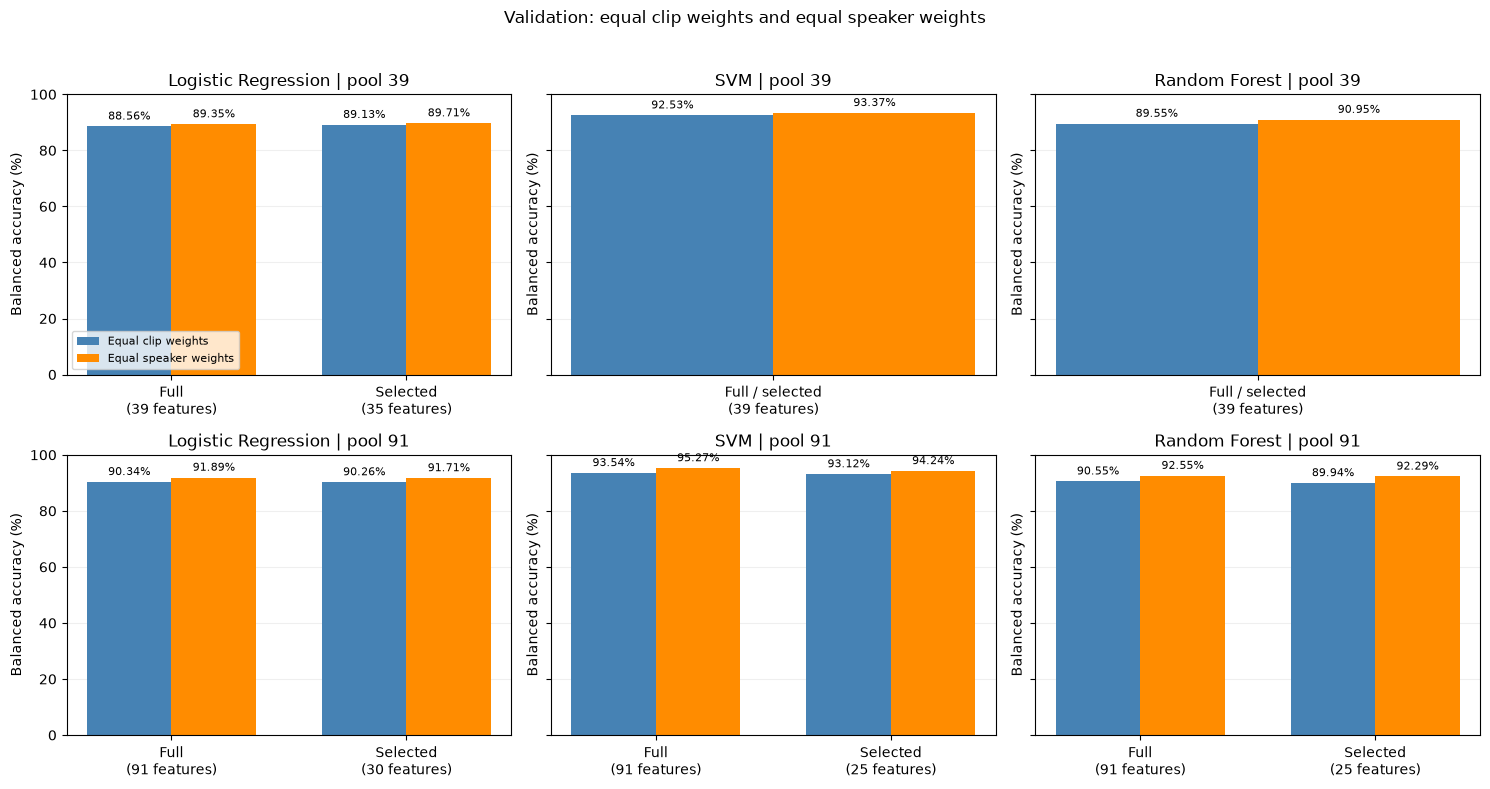

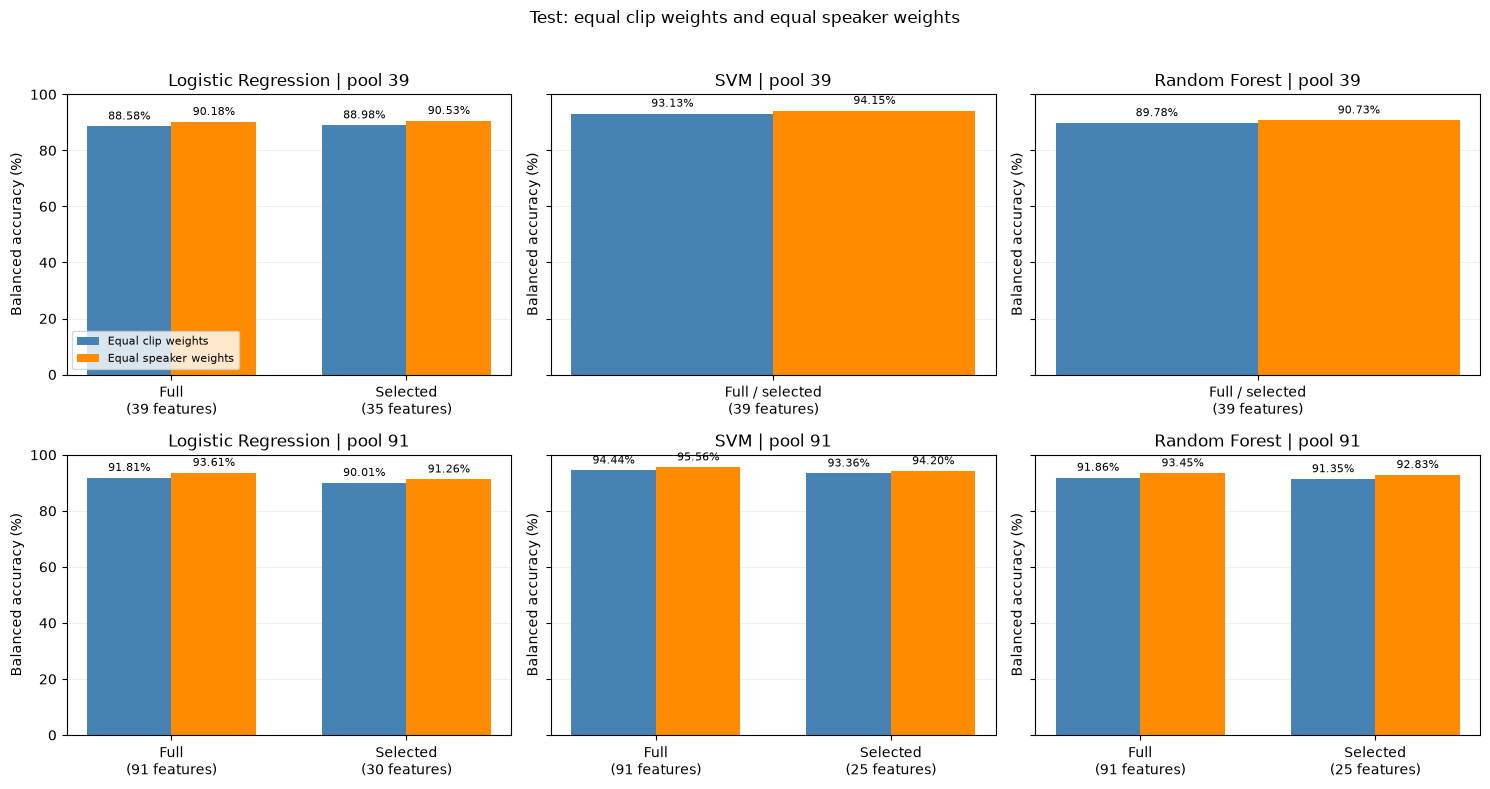

In [ ]:
for split in SPLITS:
    fig, axes = plt.subplots(len(POOLS), len(MODEL_NAMES), figsize=(15, 8), sharey=True, squeeze=False)
    width = 0.36
    for row_axes, pool in zip(axes, POOLS):
        for axis, model in zip(row_axes, MODEL_NAMES):
            rows = comparison.loc[(comparison['feature_pool'] == pool)
                & (comparison['split'] == split) & (comparison['model'] == model)]
            positions = np.arange(len(rows))
            ordinary = axis.bar(positions - width / 2, rows['ordinary_balanced_accuracy_pct'],
                                width, label='Equal clip weights', color='steelblue')
            weighted = axis.bar(positions + width / 2, rows['speaker_weighted_balanced_accuracy_pct'],
                                width, label='Equal speaker weights', color='darkorange')
            axis.bar_label(ordinary, fmt='%.2f%%', padding=3, fontsize=8)
            axis.bar_label(weighted, fmt='%.2f%%', padding=3, fontsize=8)
            axis.set_xticks(positions, [f'{r.role}\n({r.feature_count} features)' for r in rows.itertuples()])
            axis.set(title=f'{MODEL_LABELS[model]} | pool {pool}', ylim=(0, 100),
                     ylabel='Balanced accuracy (%)')
            axis.grid(axis='y', alpha=0.2)
            axis.set_axisbelow(True)
    axes[0, 0].legend(fontsize=8, loc='lower left')
    fig.suptitle(f'{split.title()}: equal clip weights and equal speaker weights')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

## 6. Read and save the comparison

A positive `clip_minus_speaker_points` means the score is higher when speakers with
more clips have more influence. A negative value means the speaker-weighted score is higher.
The gain columns compare the saved selected count with its own full-pool baseline.

Speaker weights change the scoring only. They do not make repeated clips independent,
remove recording-source effects, or prove performance on new speakers or sources.
Do not select a new model or count from these test results.

In [ ]:
for pool in POOLS:
    for split in SPLITS:
        rows = comparison.loc[(comparison['feature_pool'] == pool) & (comparison['split'] == split)]
        largest = rows.loc[rows['clip_minus_speaker_points'].abs().idxmax()]
        print(f"Pool {pool}, {split}: largest clip-minus-speaker difference is "
              f"{largest['clip_minus_speaker_points']:+.2f} percentage points "
              f"for {MODEL_LABELS[largest['model']]} ({largest['feature_count']} features).")
        for model in MODEL_NAMES:
            selected = rows.loc[(rows['model'] == model) & (rows['role'] == 'Selected')]
            if selected.empty:
                continue
            result = selected.iloc[0]
            print(f"  {MODEL_LABELS[model]}: selected-minus-full change is "
                  f"{result['ordinary_gain_from_full_points']:+.2f} points with clip weights and "
                  f"{result['speaker_weighted_gain_from_full_points']:+.2f} points with speaker weights.")

RESULTS_DIR = STUDY_DIR / 'speaker_weight_comparison'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
comparison.to_csv(RESULTS_DIR / 'score_comparison.csv', index=False)
speaker_summary.to_csv(RESULTS_DIR / 'speaker_summary.csv', index=False)
(RESULTS_DIR / 'comparison_sources.json').write_text(json.dumps({
    'dataset_id': identities['dataset_id'],
    'studies': {str(pool): {'cache_id': studies[pool]['cache_id'],
        'selected_counts': studies[pool]['selected_counts'],
        'test_prediction_source': run_rows[i]['test_prediction_source']}
        for i, pool in enumerate(POOLS)},
}, indent=2) + '\n')
print('Saved comparison:', RESULTS_DIR)

Pool 39, validation: largest clip-minus-speaker difference is -1.40 percentage points for Random Forest (39 features).
  Logistic Regression: selected-minus-full change is +0.57 points with clip weights and +0.36 points with speaker weights.
Pool 39, test: largest clip-minus-speaker difference is -1.60 percentage points for Logistic Regression (39 features).
  Logistic Regression: selected-minus-full change is +0.40 points with clip weights and +0.35 points with speaker weights.
Pool 91, validation: largest clip-minus-speaker difference is -2.35 percentage points for Random Forest (25 features).
  Logistic Regression: selected-minus-full change is -0.08 points with clip weights and -0.18 points with speaker weights.
  SVM: selected-minus-full change is -0.42 points with clip weights and -1.03 points with speaker weights.
  Random Forest: selected-minus-full change is -0.61 points with clip weights and -0.26 points with speaker weights.
Pool 91, test: largest clip-minus-speaker differen